# Matching

[All Quick Tutorials](README.md)

In observational data, assignment can depend on participants' characteristics. Matching uses pretreatment features to find similar observations in the other group, so outcomes are compared among more comparable units. A causal interpretation requires comparability on factors affecting both assignment and outcome, as well as overlap in feature values across groups.

ATE is the average treatment effect for the study population, ATT for treated units, and ATC for control units. Start with Mahalanobis distance, the HypEx default. It is especially useful when features have different scales or are correlated.

## Contents

- [What matching estimates](#matching-theory)
- [Simulate data with a known effect](#matching-generate)
- [Check baseline imbalance](#matching-imbalance)
- [Match with one neighbor](#matching-one)
- [Check the counterfactual outcome](#matching-counterfactual)
- [Match with three neighbors](#matching-many)
- [Compare estimates with the known effect](#matching-bias)
- [Estimate the effect within common support](#matching-overlap)
- [Match within segments](#matching-groups)
- [Configure distance and feature weights](#matching-weights)
- [Check sensitivity to feature scale](#matching-scale)

<a id="matching-theory"></a>

## What matching estimates

Let $Y(1)$ and $Y(0)$ be the potential outcomes and $T$ the treatment assignment. The three average effects refer to different populations.

$$
\mathrm{ATE}=\mathbb E[Y(1)-Y(0)],\quad
\mathrm{ATT}=\mathbb E[Y(1)-Y(0)\mid T=1],\quad
\mathrm{ATC}=\mathbb E[Y(1)-Y(0)\mid T=0].
$$

For a treated unit, approximate the unobserved outcome under control by averaging the outcomes of its $k$ control neighbors $\mathcal N_0(i)$.

$$
\widehat Y_i(0)=\frac{1}{k}\sum_{j\in\mathcal N_0(i)}Y_j,\qquad
\widehat{\mathrm{ATT}}=\frac{1}{n_T}\sum_{i:T_i=1}\bigl(Y_i-\widehat Y_i(0)\bigr).
$$

This is the basic estimator before adjustment for remaining differences between matched units. A causal interpretation requires comparability on factors affecting both assignment and outcome, overlap, and no effect of one unit's assignment on another unit's outcome. [Abadie and Imbens, 2006](https://scholar.harvard.edu/files/imbens/files/large_sample_properties_of_matching_estimators_for_average_treatment_effects.pdf)

<a id="matching-generate"></a>

## Simulate data with a known effect

Simulate 5,000 observations with $X_i\sim\mathrm{Uniform}(0,10)$. The probability of treatment increases with this baseline feature.

$$
P(T_i=1\mid X_i)=\min\bigl(1,\max(0,(X_i-2)/6)\bigr).
$$

When $X\le 2$, only control is possible. When $X\ge 8$, only treatment is possible. Both are possible in $(2,8)$, so the distributions are shifted and overlap only partially.

Construct the potential outcomes from a baseline $Y_i(0)=20+4X_i+\varepsilon_i$ and a constant effect $Y_i(1)=Y_i(0)+5$. The true ATE, ATT, and ATC all equal 5. Pass only the observed outcome $Y_i=Y_i(0)+5T_i$ to HypEx. Keep the true $Y_i(0)$ separately to check the predictions for treated units.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from hypex import HomogeneityTest, Matching
from hypex.dataset import Dataset, FeatureRole, GroupingRole, TargetRole, TreatmentRole

rng = np.random.default_rng(7)
x = rng.uniform(0, 10, size=5000)
overlap_start, overlap_end = 2, 8
propensity = np.clip((x - overlap_start) / (overlap_end - overlap_start), 0, 1)
treatment = rng.binomial(1, propensity)
true_ate = 5.0
y0 = pd.Series(20 + 4 * x + rng.normal(0, 0.4, size=len(x)), name="known_y0")
frame = pd.DataFrame(
    {"Treatment": treatment, "Target": y0 + true_ate * treatment, "X_lag_1": x}
)
frame.head(3)

,Treatment,Target,X_lag_1
0,1,50.297141,6.250955
1,1,61.344805,8.972138
2,1,55.819743,7.756857


Each row is one observation. `X_lag_1` represents $X$, `Treatment` represents $T$, and `Target` is the observed outcome. Because higher $X$ increases both the probability of treatment and the outcome, the raw difference in means reflects both the treatment effect and baseline imbalance.

<a id="matching-imbalance"></a>

## Check baseline imbalance

Give the historical feature `TargetRole` so `HomogeneityTest` compares it across groups before matching. The t-test compares means. The KS test compares distributions.

In [2]:
baseline_data = Dataset(
    roles={"Treatment": TreatmentRole(), "X_lag_1": TargetRole()},
    data=frame[["Treatment", "X_lag_1"]],
)
HomogeneityTest().execute(baseline_data).summary

,feature,group,control mean,test mean,difference,difference %,ci lower,ci upper,TTest pass,TTest p-value,KSTest pass,KSTest p-value
0,X_lag_1,1,2.803826,7.216167,4.412341,157.368585,4.308997,4.515685,NOT OK,0.0,NOT OK,0.0


Mean `X_lag_1` is about 2.80 in control and 7.22 in treatment. The difference is 4.41, with an interval from 4.31 to 4.52. Both tests detect baseline imbalance. Extremely small p-values print as `0.0` due to numerical precision. Use the difference in means to assess the size of the imbalance.

Plot the distributions of `X_lag_1` before matching. Use the same bins and normalize to density so group size does not determine bar height. The shaded band marks the region where the generator allows both groups.

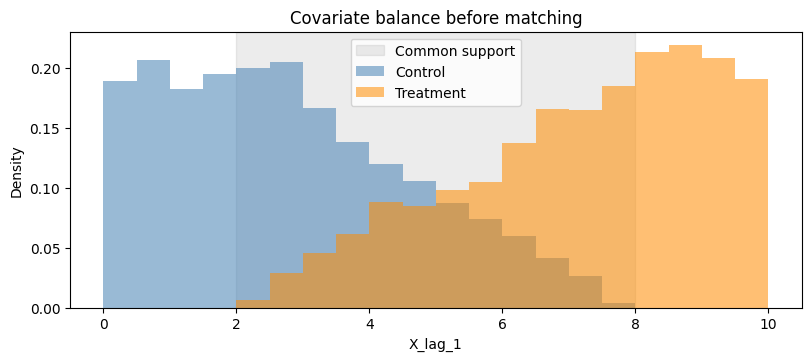

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
ax.axvspan(overlap_start, overlap_end, color="gray", alpha=0.15, label="Common support")
bins = np.linspace(0, 10, 21)
for group, label, color in [(0, "Control", "steelblue"), (1, "Treatment", "darkorange")]:
    values = frame.loc[frame["Treatment"] == group, "X_lag_1"]
    ax.hist(values, bins=bins, density=True, alpha=0.55, color=color, label=label)
ax.set(xlabel="X_lag_1", ylabel="Density", title="Covariate balance before matching")
ax.legend()
plt.show()

The control distribution is shifted left and the treatment distribution right. Below 2, all observations are in control. Above 8, all are in treatment. In these tails, nearest-neighbor matching must borrow observations from another part of the scale.

<a id="matching-one"></a>

## Match with one neighbor

Use `FeatureRole` on `X_lag_1` for finding neighbors and `TargetRole` on `Target` for estimating the effect. Specify `distance="mahalanobis"` explicitly. With one numeric feature, this is the absolute difference divided by the feature's common scale. A later example shows what changes when several features are present.

`distance="l2"` works for a single feature or comparable scales when you can ignore correlations. `quality_tests` accepts one test or a list drawn from `"ks-test"`, `"t-test"`, and `"chi2-test"`. `"auto"` runs the built-in checks. This example chooses only KS with `quality_tests="ks-test"`.

For the effect report alone, use `Matching()` with these roles. Mahalanobis distance and `bias_estimation=True` are defaults. `extract_full_data` and `compute_indexes` are off by default. This version requires both flags to populate `indexes` and the matched columns in `full_data`.

In [4]:
matching_data = Dataset(
    roles={
        "Treatment": TreatmentRole(),
        "Target": TargetRole(),
        "X_lag_1": FeatureRole(),
    },
    data=frame,
)
matched = Matching(
    distance="mahalanobis",
    bias_estimation=True,
    quality_tests="ks-test",
    extract_full_data=True,
    compute_indexes=True,
).execute(matching_data)
matched.summary

,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,4.7507,0.2384,0.0,4.2834,5.2180
ATC,4.9053,0.2510,0.0,4.4133,5.3973
ATE,4.8294,0.1736,0.0,4.4891,5.1697


On the full sample, the adjusted ATE is 4.829. The confidence interval from 4.489 to 5.170 includes the true effect of 5. For observations outside common support, the adjustment extrapolates the linear outcome model.

Read the KS diagnostic for the feature after matching.

In [5]:
matched.quality_results

,feature,group,KSTest pass,KSTest p-value
0,X_lag_1,0,NOT OK,2.697489e-188
1,X_lag_1,1,NOT OK,3.578549e-230


The KS checks still detect a difference in both matching directions. Nearest-neighbor matching can leave imbalance when some units have no similar counterpart in the other group. Because neighbors may be reused, interpret this report as a balance diagnostic. [Matching quality guide](../how_to_guide/matching-quality.ipynb)

Open `indexes` to see which rows HypEx matched.

In [6]:
matched.indexes.iloc[:5]

,indexes_0
0,4502
1,4627
2,4627
3,2813
4,2336


The index on the left identifies the original observation. The value in `indexes_0` identifies its neighbor.

<a id="matching-counterfactual"></a>

## Check the counterfactual outcome

For a treated unit, use the observed outcome of its nearest control neighbor as a prediction of its outcome without treatment. Compare that prediction before regression adjustment (`Target_matched_0`) with the true $Y_i(0)$, which is available here because the data are simulated.

Filter and select columns through HypEx. Use the public `data` property to join the true outcome from the simulation.

In [7]:
pairs = matched.full_data
pair_columns = ["X_lag_1", "X_lag_1_matched_0", "Target_matched_0"]
treated_pairs = pairs[pairs["Treatment"] == 1].select(pair_columns)
predicted_y0 = treated_pairs.data.join(y0)
predicted_y0["absolute diff"] = (
    predicted_y0["Target_matched_0"] - predicted_y0["known_y0"]
).abs()
predicted_y0.head(3).round(3)

,X_lag_1,X_lag_1_matched_0,Target_matched_0,known_y0,absolute diff
0,6.251,6.262,45.299,45.297,0.002
1,8.972,7.751,51.435,56.345,4.909
2,7.757,7.751,51.435,50.820,0.616


Compare the first two feature columns. Observation 1 has a feature value above 8, and its control neighbor is below 8. The error in predicting the untreated outcome is about 4.91. Outside common support, even the nearest neighbor can be far away.

<a id="matching-many"></a>

## Match with three neighbors

`n_neighbors` sets the number of neighbors per observation and defaults to one. Choose three. On pandas, `faiss_mode="base"` selects exact search, `"fast"` selects approximate search, and `"auto"` chooses based on the data size. Display the original feature value and values for all three neighbors.

This example compares all three matched values directly. The automatic balance checks use only the best neighbor, so disable them with `quality_tests=[]`.

Changing `n_neighbors` is enough to request three neighbors. `faiss_mode="base"` fixes the search mode, and both extraction flags make the matched columns available. The example spells out the default `distance="mahalanobis"` to identify the distance used for the comparison.

In [8]:
neighbors = Matching(
    distance="mahalanobis",
    faiss_mode="base",
    n_neighbors=3,
    quality_tests=[],
    extract_full_data=True,
    compute_indexes=True,
).execute(matching_data)
columns = ["X_lag_1", "X_lag_1_matched_0", "X_lag_1_matched_1", "X_lag_1_matched_2"]
neighbors.full_data.select(columns).iloc[:3]

,X_lag_1,X_lag_1_matched_0,X_lag_1_matched_1,X_lag_1_matched_2
0,6.250955,6.262500,6.264667,6.235973
1,8.972138,7.751428,7.656236,7.637419
2,7.756857,7.751428,7.656236,7.637419


`full_data` contains `X_lag_1_matched_0`, `X_lag_1_matched_1`, and `X_lag_1_matched_2`. Compare them with the original feature column to see how close each neighbor is.

<a id="matching-bias"></a>

## Compare estimates with the known effect

`bias_estimation=True` applies a regression adjustment for remaining feature differences between an observation and its neighbor. Turn it off with `bias_estimation=False` while keeping the same search and one neighbor. Compare the raw difference in means, matching, and matching with bias adjustment.

`bias_estimation` controls the adjustment. `quality_tests=[]` disables the separate diagnostic report. Because this comparison uses effect estimates, leave the neighbor extraction flags off.

The example spells out the default `distance="mahalanobis"` as the shared setting for both matching runs.

Display the full `summary` for matching without bias adjustment. The one-neighbor section shows the adjusted report. To compare absolute errors, read the `ATE` row and `Effect Size` column through `get_values()`.

In [9]:
unadjusted = Matching(
    distance="mahalanobis",
    bias_estimation=False,
    quality_tests=[],
).execute(matching_data)
display(unadjusted.summary)

difference = frame.groupby("Treatment")["Target"].mean()
estimates = pd.Series(
    {
        "Raw group difference": difference.loc[1] - difference.loc[0],
        "Matching without bias adjustment": unadjusted.summary.get_values(
            row="ATE", column="Effect Size"
        ),
        "Matching with bias adjustment": matched.summary.get_values(
            row="ATE", column="Effect Size"
        ),
    },
    name="estimate",
)
comparison = estimates.to_frame()
comparison["absolute error vs true ATE"] = (estimates - true_ate).abs()
comparison.round(4)

,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,6.8592,1.2269,0.0,4.4545,9.2639
ATC,6.6242,1.1780,0.0,4.3154,8.9330
ATE,6.7396,0.8516,0.0,5.0705,8.4088


,estimate,absolute error vs true ATE
Raw group difference,22.6314,17.6314
Matching without bias adjustment,6.7396,1.7396
Matching with bias adjustment,4.8294,0.1706


The true ATE is 5. The raw difference in means is 22.63, matching gives 6.74, and bias-adjusted matching gives 4.83. In this simulation, the adjustment reduces absolute error from 1.74 to 0.17. Estimates in the nonoverlapping tails depend on the assumed linear relationship between the feature and the outcome.

<a id="matching-overlap"></a>

## Estimate the effect within common support

Keep observations with `X_lag_1` between 2 and 8, where the generator permits either assignment. Run matching on that subset to estimate the effect for observations within common support.

The input filter defines common support. `quality_tests=[]` leaves the effect report. The call spells out the defaults `distance="mahalanobis"` and `bias_estimation=True` to show the settings used on the subset.

In the full `summary`, find `ATE`. `Effect Size` gives the estimate. `CI Lower` and `CI Upper` give the interval bounds.

In [10]:
in_overlap = frame["X_lag_1"].between(overlap_start, overlap_end, inclusive="neither")
overlap_data = Dataset(
    roles=matching_data.roles,
    data=frame.loc[in_overlap].copy(),
)
overlap_result = Matching(
    distance="mahalanobis",
    bias_estimation=True,
    quality_tests=[],
).execute(overlap_data)
print("Observations in common support:", in_overlap.sum())
overlap_result.summary

Observations in common support: 2996


,Effect Size,Standard Error,P-value,CI Lower,CI Upper
ATT,4.9618,0.0625,0.0,4.8394,5.0843
ATC,4.9271,0.0629,0.0,4.8039,5.0503
ATE,4.9438,0.0468,0.0,4.8521,5.0354


There are 2,996 observations within common support. Their estimated ATE is about 4.94. Because the simulated effect is constant, the benchmark for the subset is also 5. If the effect varies with the features, restricting the sample changes the target population and can change the estimate.

<a id="matching-groups"></a>

## Match within segments

`group_match=True` restricts the search to segments identified by a `GroupingRole` column. Each segment needs both control and treated units. Define two segments from the historical feature. The distance uses only numeric `X_lag_1`, so use `encode_categories=False`. The default `True` encodes string features with `FeatureRole`.

Use both `group_match=True` and `GroupingRole` for within-segment search. `encode_categories=False` skips encoding because the matching feature is numeric. For string columns with `FeatureRole`, keep the default `encode_categories=True`. Use `quality_tests=[]` to focus on segment-level effect estimates.

The call spells out the default `distance="mahalanobis"` to identify the distance used within each segment.

In [11]:
frame["segment"] = (frame["X_lag_1"] >= 5).map({False: "low", True: "high"})
grouped_data = Dataset(
    roles={
        "Treatment": TreatmentRole(),
        "Target": TargetRole(),
        "X_lag_1": FeatureRole(),
        "segment": GroupingRole(),
    },
    data=frame,
)
grouped = Matching(
    group_match=True,
    distance="mahalanobis",
    encode_categories=False,
    quality_tests=[],
).execute(grouped_data)
grouped.summary

,high Effect Size,high Standard Error,high P-value,high CI Lower,high CI Upper,low Effect Size,low Standard Error,low P-value,low CI Lower,low CI Upper
ATC,4.9968,0.0538,0.0,4.8913,5.1023,4.8871,0.2806,0.0,4.3372,5.4370
ATE,4.7092,0.2811,0.0,4.1582,5.2601,4.8972,0.2388,0.0,4.4292,5.3652
ATT,4.6573,0.3310,0.0,4.0086,5.3061,4.9539,0.0433,0.0,4.8691,5.0387


The report contains separate estimates for `high` and `low`. Interpret their point estimates in light of the wide intervals.

<a id="matching-weights"></a>

## Configure distance and feature weights

L2 measures distance in the original coordinates. Mahalanobis distance uses the covariance matrix $\Sigma$ to account for feature scales and correlations.

$$
d_{L2}(x,x')=\sqrt{\sum_j(x_j-x'_j)^2},\qquad
d_M(x,x')=\sqrt{(x-x')^\top\Sigma^{-1}(x-x')}.
$$

For `distance="mahalanobis"`, `weights` sets the relative importance of features. With `None`, HypEx applies no extra weights. Weights can change the order of neighbors when different features favor different candidates.

Create a small dataset. Historical sales and visits are numeric features. `channel` is categorical, so use `encode_categories=True` for the search.

In [12]:
shoppers = pd.DataFrame(
    {
        "group": [0] * 6 + [1] * 6,
        "sales": [4, 6, 8, 5, 7, 9, 6, 7, 10, 7, 8, 11],
        "past_sales": [2, 4, 6, 2, 4, 6, 3, 4, 7, 2, 5, 7],
        "visits": [1, 3, 5, 1, 3, 5, 5, 3, 1, 5, 3, 1],
        "channel": ["web"] * 3 + ["app"] * 3 + ["web"] * 3 + ["app"] * 3,
    }
)
shopper_data = Dataset(
    roles={
        "group": TreatmentRole(),
        "sales": TargetRole(),
        "past_sales": FeatureRole(),
        "visits": FeatureRole(),
        "channel": FeatureRole(),
    },
    data=shoppers,
)
shopper_data.iloc[:3]

,group,sales,past_sales,visits,channel
0,0,4,2,1,web
1,0,6,4,3,web
2,0,8,6,5,web


The table shows the outcome, two numeric features, and one categorical feature. The search uses columns with `FeatureRole`.

Compare neighbor indices while changing only `weights`. The second run gives historical sales a weight of 4 relative to the standard weight of 1.

The options spell out two defaults, `distance="mahalanobis"` and `encode_categories=True`. Both runs use the same extraction flags. `quality_tests=[]` disables diagnostics for this comparison of neighbors. The second run changes only the weights used with Mahalanobis distance.

In [13]:
options = {
    "distance": "mahalanobis",
    "encode_categories": True,
    "quality_tests": [],
    "extract_full_data": True,
    "compute_indexes": True,
}
unweighted = Matching(**options).execute(shopper_data)
weighted = Matching(weights={"past_sales": 4.0}, **options).execute(shopper_data)

unweighted.indexes.merge(
    weighted.indexes.rename({"indexes_0": "indexes_0_weighted"}),
    left_index=True,
    right_index=True,
)

,indexes_0,indexes_0_weighted
0,7,9
1,7,7
2,10,10
3,7,9
4,7,7
...,...,...
7,1,1
8,1,2
9,1,0
10,1,1


Row 0's neighbor changes from row 7 to row 9. Historical sales are 2 for both row 0 and its new neighbor. Giving sales more weight changed the selected neighbor in this example.

<a id="matching-scale"></a>

## Check sensitivity to feature scale

You can express sales in units of currency or in hundredths of a unit. Multiply historical sales by 100 and leave the other features alone. Count how many rows get a different neighbor after this change under Mahalanobis and L2 distances. Keep the inputs and other settings the same for both distance comparisons.

For the L2 comparison, change only `distance` and omit `weights`. The extraction and encoding settings come from `options`.

In [14]:
scaled_data = Dataset(
    roles=shopper_data.roles,
    data=shoppers.assign(past_sales=shoppers["past_sales"] * 100),
)
scaled_mahalanobis = Matching(**options).execute(scaled_data)

l2_options = {**options, "distance": "l2"}
l2 = Matching(**l2_options).execute(shopper_data)
scaled_l2 = Matching(**l2_options).execute(scaled_data)

def changed_neighbors(original, scaled):
    original_ids = original.indexes.sort().to_numpy()
    scaled_ids = scaled.indexes.sort().to_numpy()
    return int(np.count_nonzero(original_ids != scaled_ids))


{
    "Mahalanobis": changed_neighbors(unweighted, scaled_mahalanobis),
    "L2": changed_neighbors(l2, scaled_l2),
}

{'Mahalanobis': 0, 'L2': 5}

Changing units preserves every Mahalanobis match and changes five L2 matches in this example. L2 is useful when feature scales are comparable and raw coordinate differences are meaningful. When scales differ or features are correlated, start with Mahalanobis and check the resulting matches.

See how to [run matching with the same settings on pandas and Spark](SparkBackend.ipynb#spark-matching).

See the [balance guide](../how_to_guide/matching-quality.ipynb#matching-mixed-checks) for numeric and categorical checks and the [FAISS guide](../how_to_guide/matching-faiss.ipynb) for choosing exact or approximate search.